<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/handbook/FDS_Handbook_4Encoders_TabPFN35_Resume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Handbook | GRU · Matched Transformer · SIGMA · Transformer + Time2Vec
외부 합성 카드결제 데이터에서 기존 방법론의 성능 경향 재현 검증. **Seed 0, 22 runs** (2 current-only baselines + 4 encoders × 5 windows). TabPFN 3.5 pretrained, no fine-tuning. 기존 데이터의 가중치를 전이하지 않고 동일 설계로 새로 학습한다.

- `processed/handbook/full_v1.parquet`, `history_3h.parquet`, `settings.json` 사용. 기존 `processed/full` 수정 없음.
- 현재 거래 3개 특징, 과거 구간 6개 특징, 3시간 집계, 32차원 공통 출력. 단말기 ID는 현재 거래 입력에서 제외하고 과거 고유 단말기 수에만 사용. 시나리오 및 고객 ID는 모델 입력에서 제외.
- 기존 9,996 라벨 예산, train 비율 유지, fit/tune 80:20. 기존 데이터의 양성 38건을 강제하지 않음. Val 전체로 threshold 설정, Test 전체 평가. 모든 모델에 동일 행 사용. Test의 이전 구간 거래 **특징만** 순차 조회 허용 (라벨 사용 없음). 모든 모델 설정은 평가 전에 고정.
- 1/2/7/14/30일, GRU 32, Matched TF 내부 20/FF32, SIGMA 64/state32/expand2/conv4/recent5, Time2Vec TF 내부 32/FF64/time8. Transformer 1층/4 heads, GELU/dropout .1. SIGMA dropout .2. 학습 AdamW, lr .001, 20 epochs, patience 3, logical batch 256.
- 실행: 위에서부터 공통 셀 실행 후 각 Part 셀을 선택 실행하거나 Run all. 결과/예측/완료 Encoder 체크포인트 자동 저장. 재접속 시 공통 셀 재실행 후 원하는 Part 실행. 완료된 결과 건너뜀. 미완료 Encoder 학습은 다시 시작할 수 있음.
- 비교는 단일 Seed 예비 실험이며 실제 사기 일반화 또는 Time2Vec 단독 효과의 독립 입증은 아님 (Matched와 Time2Vec 모델 내부 폭이 다름). SIGMA는 원 논문 추천 모델을 FDS에 맞게 변형한 기존 구현이며 native CUDA 커널이 아님.

In [1]:
# 1. Colab 설치: 기존 실험 버전 유지
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError
packages={'tabpfn':'10.2.0','lightgbm':'4.7.0','pyarrow':'26.0.1'}
need=[]
for p,v in packages.items():
    try: installed=version(p)
    except PackageNotFoundError: installed=None
    if installed!=v: need.append(f'{p}=={v}')
if need: subprocess.check_call([sys.executable,'-m','pip','install','-q',*need])
# 이미 import된 패키지가 변경됐다면 런타임 재시작

In [2]:
# 2. 설정 / 경로 / 재현성
from google.colab import drive, userdata
import os, json, gc, time, hashlib, random, uuid, math, ast, re, urllib.request
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from torch import nn
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve, auc, roc_curve
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/26-2_AI_project/processed/handbook')
OUT=ROOT/'four_encoders_tabpfn35_v1'
for d in [OUT,OUT/'runs',OUT/'checkpoints',OUT/'provenance',OUT/'plots',OUT/'sessions']:
    d.mkdir(parents=True,exist_ok=True)
S=json.loads((ROOT/'settings.json').read_text())
BASE=S['BASE_FEATURES']; CAT=S['CATEGORICAL_FEATURES']; HIST=S['HISTORY_FEATURES']; CAT_IDX=[BASE.index(c) for c in CAT]
assert BASE==['amount_log','time_band','weekday'] and CAT==['time_band','weekday']
assert HIST==['count','total','mean','max','terminal_count','observed'] and S['BIN_HOURS']==3
assert S['LABEL']=='label' and S['USER']=='customer_id' and S['TERMINAL']=='terminal_id'
assert S['HISTORY_LOG_TRANSFORMED'] is True
DH=len(HIST); AGG=HIST[:-1]; HIDDEN=32; TIME_DIM=8
RUN_DAYS=[1,2,7,14,30]; RUN_SEEDS=[0]  # 변경 시 새 실험 폴더 사용; 모든 모델 동일 seed
LABEL_BUDGET=9996; GRU_EPOCHS=20; GRU_PATIENCE=3; GRU_LR=1e-3; GRU_BATCH=256
TF_DIM=20; TF_HEADS=4; TF_LAYERS=1; TF_FF=32; TF_DROPOUT=.1
SIGMA_DIM=64; SIGMA_STATE=32; SIGMA_CONV=4; SIGMA_EXPAND=2; SIGMA_LAYERS=1; SIGMA_DROPOUT=.2; KEEP_RECENT=5
SIGMA_MICRO_BATCH=32; SIGMA_INFER_BATCH=128
SIGMA_COMMIT='a3f63751503eca869338fc9c8b24a05fa128c6ef'
FINAL_EST=4; PRED_BATCH=4096; MAX_TREES=2000; LGB_PATIENCE=50; TARGET_FPR=.001; REVIEW_TARGET_RECALL=.30
THREADS=min(8,os.cpu_count() or 1); DEVICE='cuda'; SESSION=uuid.uuid4().hex[:12]
assert torch.cuda.is_available(), 'GPU 런타임으로 변경하세요'
assert hasattr(ModelVersion,'V3_5'), 'TabPFN 3.5 API 필요'
if not os.environ.get('TABPFN_TOKEN'):
    for k in ('TABPFN_TOKEN','TABPFN_API_KEY'):
        try: token=userdata.get(k)
        except Exception: continue
        if token: os.environ['TABPFN_TOKEN']=token; del token; break
assert os.environ.get('TABPFN_TOKEN'), 'Colab Secrets의 TABPFN_TOKEN 확인'
ENV=dict(gpu=torch.cuda.get_device_name(0),cuda=torch.version.cuda,versions={p:version(p) for p in ['tabpfn','torch','lightgbm','pyarrow','numpy','pandas','scikit-learn']})
NAMES={'gru':'GRU','matched':'Matched Transformer','sigma':'SIGMA','time2vec':'Transformer + Time2Vec'}
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()
def write_json(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False)); os.replace(tmp,p)
def write_npz(p,**kw):
    tmp=p.with_suffix(p.suffix+'.tmp')
    with open(tmp,'wb') as f: np.savez_compressed(f,**kw)
    os.replace(tmp,p)
def write_csv(p,df):
    tmp=p.with_suffix(p.suffix+'.tmp'); df.to_csv(tmp,index=False); os.replace(tmp,p)
CONFIG=dict(design='handbook_4enc_v1',files={n:sha(ROOT/n) for n in ['full_v1.parquet','history_3h.parquet','settings.json']},base=BASE,cat=CAT,history=HIST,days=RUN_DAYS,seeds=RUN_SEEDS,budget=LABEL_BUDGET,split='train_fit_tune_80_20_val_cal_test_full',history_policy='rolling_past_bins_only_no_labels',hidden=HIDDEN,time_dim=TIME_DIM,gru_epochs=GRU_EPOCHS,patience=GRU_PATIENCE,lr=GRU_LR,batch=GRU_BATCH,tf_matched=[TF_DIM,TF_FF,TF_HEADS,TF_LAYERS,TF_DROPOUT],tf_time=[32,64,4,1,.1],sigma=[SIGMA_DIM,SIGMA_STATE,SIGMA_CONV,SIGMA_EXPAND,SIGMA_LAYERS,SIGMA_DROPOUT,KEEP_RECENT,SIGMA_MICRO_BATCH,SIGMA_INFER_BATCH,SIGMA_COMMIT],n_estimators=FINAL_EST,pred_batch=PRED_BATCH,max_trees=MAX_TREES,lgb_patience=LGB_PATIENCE,target_fpr=TARGET_FPR,review_recall=REVIEW_TARGET_RECALL,software=ENV['versions'])
cp=OUT/'config.json'
if cp.exists(): assert json.loads(cp.read_text())==CONFIG, '설정/데이터/라이브러리 변경: 새 OUT 사용'
else: write_json(cp,CONFIG)
write_json(OUT/'sessions'/f'{SESSION}.json',ENV)
print(ENV); print('Output:',OUT)

Mounted at /content/drive
{'gpu': 'NVIDIA A100-SXM4-40GB', 'cuda': '13.0', 'versions': {'tabpfn': '10.2.0', 'torch': '2.14.1+cu130', 'lightgbm': '4.7.0', 'pyarrow': '26.0.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}}
Output: /content/drive/MyDrive/26-2_AI_project/processed/handbook/four_encoders_tabpfn35_v1


In [3]:
# 3. 공통 행 분할: 원본 비율을 보존한 9,996개 라벨 예산
cols=list(dict.fromkeys(BASE+['label','customer_id','terminal_id','bin_id','date','split','amount','transaction_id','fraud_scenario']))
df=pd.read_parquet(ROOT/'full_v1.parquet',columns=cols)
assert df.index.equals(pd.RangeIndex(len(df))) and not df.isna().any().any()
assert df.transaction_id.is_unique and set(df.label.unique())=={0,1}
assert set(df.split.unique())=={'train','val','test'}
y=df.label.to_numpy(np.int8); split=df.split.to_numpy(); bins=df.bin_id.to_numpy(np.int64)
train=np.flatnonzero(split=='train'); cal=np.flatnonzero(split=='val'); ev=np.flatnonzero(split=='test')
assert bins[train].max()<bins[cal].min() and bins[cal].max()<bins[ev].min()
assert all(set(y[a])=={0,1} for a in [train,cal,ev])
weights=np.ones(len(ev)); cal_weights=np.ones(len(cal))
P={}; rate=float(y[train].mean()); npos=round(LABEL_BUDGET*rate)
assert 5<=npos<LABEL_BUDGET and (y[train]==1).sum()>=npos and (y[train]==0).sum()>=LABEL_BUDGET-npos
for seed in RUN_SEEDS:
    rng=np.random.default_rng(seed)
    rows=np.sort(np.r_[rng.choice(train[y[train]==1],npos,replace=False),rng.choice(train[y[train]==0],LABEL_BUDGET-npos,replace=False)])
    fit,tune=train_test_split(rows,test_size=.2,random_state=seed,stratify=y[rows])
    fit,tune=np.sort(fit),np.sort(tune)
    assert not np.intersect1d(fit,tune).size and set(y[fit])==set(y[tune])=={0,1}
    P[seed]=dict(enc=fit,clf=fit,tune=tune)
    print(f'Seed {seed}: fit {len(fit):,} (fraud {y[fit].sum()}), tune {len(tune):,} (fraud {y[tune].sum()})')
row_data=dict(cal=cal,eval=ev,**{f'{k}_{s}':v for s,d in P.items() for k,v in d.items()})
rp=OUT/'rows.npz'
if rp.exists():
    with np.load(rp) as old:
        assert set(old.files)==set(row_data) and all(np.array_equal(old[k],v) for k,v in row_data.items())
else: write_npz(rp,**row_data)
print(f'Train rate={rate:.6%}; sample positives={npos}; calibration={len(cal):,}; Test={len(ev):,}')
display(df.groupby('split').label.agg(['size','sum','mean']).reindex(['train','val','test']))

Seed 0: fit 7,996 (fraud 65), tune 2,000 (fraud 16)
Train rate=0.814269%; sample positives=81; calibration=258,490; Test=268,675


,size,sum,mean
split,,,
train,1226990,9991,0.008143
val,258490,2308,0.008929
test,268675,2382,0.008866


In [4]:
# 4. Sparse history index / no current bin / no future bin
# Use saved log-transformed aggregates (no second log). Validate independently against raw features.
assert (bins>=0).all() and np.all(bins[1:]>=bins[:-1])
t=bins.copy(); B=int(t.max())+1
u,customers=pd.factorize(df.customer_id,sort=False); u=u.astype(np.int64)
assert (u>=0).all() and int(u.max())*B+B<np.iinfo(np.int64).max
key=u*B+t
hist=pd.read_parquet(ROOT/'history_3h.parquet',columns=['customer_id','bin_id']+AGG)
hu=customers.get_indexer(hist.customer_id); ht=hist.bin_id.to_numpy(np.int64)
assert (hu>=0).all() and (ht>=0).all() and (ht<B).all()
hk=hu.astype(np.int64)*B+ht; order=np.argsort(hk); K=hk[order]; V=hist[AGG].to_numpy(np.float32)[order]
assert len(K)>0 and np.all(K[1:]>K[:-1]) and np.isfinite(V).all() and (V>=0).all()
# All observed bins must agree with the original transactions, including grouping/count.
raw=df.assign(_key=key).groupby('_key',sort=True).agg(count=('amount','size'),total=('amount','sum'),mean=('amount','mean'),max=('amount','max'),terminal_count=('terminal_id','nunique'))
assert np.array_equal(raw.index.to_numpy(),K)
np.testing.assert_allclose(V,np.log1p(raw[AGG].to_numpy(np.float64)),rtol=2e-6,atol=2e-6)
static=df[BASE].copy()
for c in CAT: static[c]=static[c].astype('int32')
assert np.isfinite(static.to_numpy(np.float64)).all()
scenario=df.fraud_scenario.to_numpy(); transaction_ids=df.transaction_id.to_numpy()
del raw,hist,hk,order,hu,ht,df; gc.collect()

def gather(rows,days):
    rows=np.asarray(rows,dtype=np.int64); L=8*days
    assert L>0
    tt=t[rows,None]-np.arange(L,0,-1,dtype=np.int64)[None,:]
    observed=tt>=0
    keys=u[rows,None]*B+np.maximum(tt,0)
    ix=np.searchsorted(K,keys); safe=np.minimum(ix,len(K)-1)
    hit=observed & (ix<len(K)) & (K[safe]==keys)
    z=np.zeros((len(rows),L,DH),np.float32)
    z[hit,:DH-1]=V[safe[hit]]; z[:,:,DH-1]=observed
    return z
r=P[RUN_SEEDS[0]]['enc'][:4]
assert gather(r,1).shape==(len(r),8,DH)
assert np.array_equal(gather(r,30)[:,-8:],gather(r,1))
# Direct audit a few sampled rows: one customer, strictly previous bins only.
for row in np.r_[r,cal[:2],ev[:2]]:
    z=gather([row],2)[0]
    for j,b in enumerate(range(t[row]-16,t[row])):
        if b<0: assert not z[j].any(); continue
        i=np.searchsorted(K,u[row]*B+b)
        expected=V[i] if i<len(K) and K[i]==u[row]*B+b else np.zeros(DH-1)
        np.testing.assert_array_equal(z[j,:-1],expected); assert z[j,-1]==1
print('History index verified:',len(K),'customer × bin groups')

History index verified: 1447923 customer × bin groups


In [5]:
def elapsed_features(z):
    assert z.ndim==3 and z.shape[-1]==DH
    obs=z[:,:,DH-1]>0
    active=obs & (z[:,:,0]>0)
    idx=np.arange(z.shape[1],dtype=np.int32)[None,:]
    last=np.maximum.accumulate(np.where(active,idx,-1),axis=1)
    known=obs & (last>=0)
    hours=np.where(known,3*(idx-last),0).astype(np.float32)
    # fixed transform common to both time arms; no fitted evaluation statistics.
    dt=(np.log1p(hours)/np.log1p(720.)).astype(np.float32)
    return np.stack([dt,known.astype(np.float32)],axis=-1)
# Synthetic test: padding and pre-first-trade unknown, then 0,3,6,0,3 hours.
def test_elapsed():
    z=np.zeros((1,8,DH),np.float32); z[0,1:,DH-1]=1; z[0,[3,6],0]=1
    e=elapsed_features(z)[0]
    np.testing.assert_array_equal(e[:,1],[0,0,0,1,1,1,1,1])
    np.testing.assert_allclose(np.expm1(e[:,0]*np.log1p(720.)),[0,0,0,0,3,6,0,3],atol=1e-5)
    assert not elapsed_features(np.zeros((1,8,DH),np.float32)).any()
    # Changing a later bin cannot change earlier elapsed features.
    z2=z.copy(); z2[0,6,0]=0
    np.testing.assert_array_equal(elapsed_features(z)[:,:6],elapsed_features(z2)[:,:6])
test_elapsed()
print('Elapsed-time self-check passed')

Elapsed-time self-check passed


In [6]:
class GRUEncoder(nn.Module):
    def __init__(self):
        super().__init__(); self.gru=nn.GRU(DH,HIDDEN,batch_first=True); self.head=nn.Linear(HIDDEN,1)
    def encode(self,x): return self.gru(x)[1][-1]
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

class MatchedEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_proj=nn.Linear(DH,TF_DIM)
        # 동일 최근 시점은 모든 window에서 같은 위치 표현을 받는다.
        layer=nn.TransformerEncoderLayer(d_model=TF_DIM,nhead=TF_HEADS,dim_feedforward=TF_FF,dropout=TF_DROPOUT,activation='gelu',batch_first=True,norm_first=False)
        self.transformer=nn.TransformerEncoder(layer,num_layers=TF_LAYERS,enable_nested_tensor=False)
        self.output_proj=nn.Linear(TF_DIM,HIDDEN)
        self.head=nn.Linear(HIDDEN,1)
    def encode(self,x):
        L=x.shape[1]
        # 과거 L..1개 bin: 위치 0은 현재 거래가 아니며 입력에 포함되지 않음.
        lag=torch.arange(L,0,-1,device=x.device,dtype=torch.float32).unsqueeze(1)
        freq=torch.exp(torch.arange(0,TF_DIM,2,device=x.device,dtype=torch.float32)*(-np.log(10000.0)/TF_DIM))
        angles=lag*freq.unsqueeze(0)
        pe=torch.stack((angles.sin(),angles.cos()),dim=-1).flatten(1)
        z=self.input_proj(x)
        z=self.transformer(z+pe.to(z.dtype).unsqueeze(0))
        # 마지막 과거 bin 표현: GRU의 최종 hidden과 동일한 출력 차원.
        return self.output_proj(z[:,-1,:])
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

class Time2Vec(nn.Module):
    # Kazemi et al. form: one linear coordinate and learned periodic coordinates.
    # Input is normalized log elapsed hours, not raw seconds/calendar time.
    def __init__(self,dim=TIME_DIM):
        super().__init__()
        self.linear=nn.Linear(1,1)
        self.periodic=nn.Linear(1,dim-1)
        with torch.no_grad():
            self.periodic.weight.copy_(torch.linspace(1.,12.,dim-1).reshape(-1,1))
            self.periodic.bias.zero_()
    def forward(self,t):
        return torch.cat([self.linear(t),torch.sin(self.periodic(t))],dim=-1)

class TimeEncoder(nn.Module):
    def __init__(self,arm=None):
        super().__init__()
        self.arm="time2vec" if arm is None else arm
        assert self.arm=="time2vec"
        self.input_proj=nn.Linear(DH,HIDDEN)
        # 동일 최근 시점은 모든 window에서 같은 위치 표현을 받는다.
        layer=nn.TransformerEncoderLayer(d_model=HIDDEN,nhead=TF_HEADS,dim_feedforward=64,dropout=TF_DROPOUT,activation='gelu',batch_first=True,norm_first=False)
        self.transformer=nn.TransformerEncoder(layer,num_layers=TF_LAYERS,enable_nested_tensor=False)
        self.head=nn.Linear(HIDDEN,1)
        # Initialize common backbone first. Both time arms share same scalar and known mask.
        if self.arm=='scalar': self.temporal=nn.Linear(1,HIDDEN)
        elif self.arm=='time2vec': self.temporal=nn.Sequential(Time2Vec(),nn.Linear(TIME_DIM,HIDDEN))
    def encode(self,x):
        L=x.shape[1]
        # 과거 L..1개 bin: 위치 0은 현재 거래가 아니며 입력에 포함되지 않음.
        lag=torch.arange(L,0,-1,device=x.device,dtype=torch.float32).unsqueeze(1)
        freq=torch.exp(torch.arange(0,HIDDEN,2,device=x.device,dtype=torch.float32)*(-np.log(10000.0)/HIDDEN))
        angles=lag*freq.unsqueeze(0)
        pe=torch.stack((angles.sin(),angles.cos()),dim=-1).flatten(1)
        z=self.input_proj(x[:,:,:DH])
        z=z+pe.to(z.dtype).unsqueeze(0)
        if self.arm!='none':
            assert x.shape[-1]==DH+2
            # Known=0: no temporal contribution. Known gap=0 remains distinguishable via learned bias.
            z=z+self.temporal(x[:,:,DH:DH+1])*x[:,:,DH+1:DH+2]
        z=self.transformer(z)
        # 마지막 과거 bin 표현: GRU의 최종 hidden과 동일한 출력 차원.
        return z[:,-1,:]
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

In [7]:
# 5a. Mamba-1 selective SSM, portable PyTorch implementation (not fused CUDA kernel).
# Reference: https://github.com/state-spaces/mamba/blob/v1.1.4/mamba_ssm/modules/mamba_simple.py
import math
import torch.nn.functional as F

def affine_scan(a,b,chunk=32):
    # a,b: [B,L,D,N]; h_t = a_t*h_(t-1)+b_t, h_0=0.
    # Associative composition in each chunk, then propagate incoming state.
    state=torch.zeros_like(b[:,0]); pieces=[]
    for start in range(0,a.shape[1],chunk):
        aa=a[:,start:start+chunk]; bb=b[:,start:start+chunk]
        step=1
        while step<aa.shape[1]:
            aa,bb=(torch.cat((aa[:,:step],aa[:,step:]*aa[:,:-step]),dim=1),
                   torch.cat((bb[:,:step],bb[:,step:]+aa[:,step:]*bb[:,:-step]),dim=1))
            step*=2
        hh=bb+aa*state[:,None]; pieces.append(hh); state=hh[:,-1]
    return torch.cat(pieces,dim=1)

class Mamba(nn.Module):
    # Compatible constructor/forward for upstream SIGMA's Mamba-1 calls only.
    def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
        super().__init__(); self.d_model=d_model; self.d_state=d_state
        self.d_inner=int(d_model*expand); self.dt_rank=math.ceil(d_model/16)
        d=self.d_inner; r=self.dt_rank
        self.in_proj=nn.Linear(d_model,2*d,bias=False)
        self.conv1d=nn.Conv1d(d,d,d_conv,groups=d,padding=d_conv-1,bias=True)
        self.x_proj=nn.Linear(d,r+2*d_state,bias=False)
        self.dt_proj=nn.Linear(r,d,bias=True)
        nn.init.uniform_(self.dt_proj.weight,-r**-.5,r**-.5)
        dt=torch.exp(torch.rand(d)*(math.log(.1)-math.log(.001))+math.log(.001))
        with torch.no_grad(): self.dt_proj.bias.copy_(dt+torch.log(-torch.expm1(-dt)))
        self.A_log=nn.Parameter(torch.arange(1,d_state+1,dtype=torch.float32).log().repeat(d,1))
        self.D=nn.Parameter(torch.ones(d))
        self.out_proj=nn.Linear(d,d_model,bias=False)
    def forward(self,x):
        L=x.shape[1]; u,z=self.in_proj(x).chunk(2,dim=-1)
        u=F.silu(self.conv1d(u.transpose(1,2))[...,:L].transpose(1,2))
        delta,B,C=self.x_proj(u).split([self.dt_rank,self.d_state,self.d_state],dim=-1)
        delta=F.softplus(self.dt_proj(delta).float())
        A=-self.A_log.float().exp()
        a=torch.exp(delta[...,None]*A)
        b=(delta*u.float())[...,None]*B.float()[:,:,None,:]
        h=affine_scan(a,b)
        y=(h*C.float()[:,:,None,:]).sum(-1)+self.D.float()*u.float()
        return self.out_proj((y*F.silu(z.float())).to(x.dtype))


def load_sigma():
    global SIGMA_READY
    if SIGMA_READY: return
    import urllib.request, ast
    PROV=OUT/'provenance'; PROV.mkdir(exist_ok=True)
    for relative,name in [('model/gated_mamba.py','gated_mamba_original.py'),('LICENSE','SIGMA_LICENSE'),('model/config.yaml','config_original.yaml')]:
        dst=PROV/name
        if not dst.exists():
            url=f'https://raw.githubusercontent.com/ziwliu8/SIGMA/{SIGMA_COMMIT}/{relative}'
            with urllib.request.urlopen(url,timeout=60) as response: payload=response.read()
            assert payload, f'Empty upstream source: {url}'
            tmp=dst.with_suffix(dst.suffix+'.tmp'); tmp.write_bytes(payload); os.replace(tmp,dst)
    assert 'MIT License' in (PROV/'SIGMA_LICENSE').read_text(), 'Upstream license needs review'
    # Verify pinned upstream YAML against official architecture; no YAML dependency needed.
    import re
    original_yaml=(PROV/'config_original.yaml').read_text(encoding='utf-8')
    for key, expected in {'hidden_size':SIGMA_DIM,'d_state':SIGMA_STATE,'d_conv':SIGMA_CONV,'expand':SIGMA_EXPAND,'num_layers':SIGMA_LAYERS,'dropout_prob':SIGMA_DROPOUT}.items():
        match=re.search(r'^\s*'+re.escape(key)+r'\s*:\s*([0-9.]+)',original_yaml,flags=re.M)
        assert match and float(match.group(1))==expected, f'Official config mismatch: {key}'
    source=(PROV/'gated_mamba_original.py').read_text(encoding='utf-8')
    parsed=ast.parse(source)
    classes={node.name:ast.get_source_segment(source,node) for node in parsed.body if isinstance(node,ast.ClassDef)}
    assert {'GMambaBlock','SIGMALayers','FeedForward'}<=classes.keys()
    backbone='\n\n'.join(classes[k] for k in ['GMambaBlock','SIGMALayers','FeedForward'])
    old='flipped_input[:, :45, :] = input_tensor[:, :45, :].flip(dims=[1])'
    assert backbone.count(old)==1, 'Unexpected upstream partial flip; review before running'
    backbone=backbone.replace(old,'n = max(0, input_tensor.shape[1] - KEEP_RECENT)\n        flipped_input[:, :n, :] = input_tensor[:, :n, :].flip(dims=[1])')
    # Preserve source computation, including raw mixing weights and h1 in the second sigmoid gate.
    assert 'self.combining_weights[2]' in backbone and 'self.selective_gate_sig(h1)' in backbone
    ast.parse(backbone)
    (PROV/'backbone_adapted.py').write_text('# Requires torch, nn, F, Mamba and KEEP_RECENT from notebook. See SIGMA_LICENSE.\n'+backbone,encoding='utf-8')

    exec(compile(backbone,"SIGMA_GMamba_adapted.py","exec"),globals())
    SIGMA_READY=True

SIGMA_READY=False
class SigmaEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_proj=nn.Linear(DH,SIGMA_DIM)
        self.dropout=nn.Dropout(SIGMA_DROPOUT)
        self.LayerNorm=nn.LayerNorm(SIGMA_DIM,eps=1e-12)
        self.mamba_layers=nn.ModuleList([SIGMALayers(d_model=SIGMA_DIM,d_state=SIGMA_STATE,d_conv=SIGMA_CONV,expand=SIGMA_EXPAND,dropout=SIGMA_DROPOUT,num_layers=SIGMA_LAYERS) for _ in range(SIGMA_LAYERS)])
        self.output_proj=nn.Linear(SIGMA_DIM,HIDDEN); self.head=nn.Linear(HIDDEN,1)
        # Match upstream SIGMA outer initialization, including dt projection override.
        self.apply(self.init_weights)
    @staticmethod
    def init_weights(module):
        if isinstance(module,nn.Linear):
            nn.init.normal_(module.weight,mean=0.,std=.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module,nn.LayerNorm):
            nn.init.ones_(module.weight); nn.init.zeros_(module.bias)
    def encode(self,x):
        x=self.LayerNorm(self.dropout(self.input_proj(x)))
        for layer in self.mamba_layers: x=layer(x)
        return self.output_proj(x[:,-1,:])
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

In [8]:
# 5. Shared training / frozen embedding / checkpoint
ENCODERS={'gru':GRUEncoder,'matched':MatchedEncoder,'sigma':SigmaEncoder,'time2vec':TimeEncoder}
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True

def make_encoder(arm):
    if arm=='sigma': load_sigma()
    return ENCODERS[arm]().to(DEVICE)
def cleanup():
    gc.collect()
    if DEVICE=='cuda': torch.cuda.empty_cache()
def timed(fn):
    if DEVICE=='cuda': torch.cuda.synchronize()
    start=time.perf_counter(); ans=fn()
    if DEVICE=='cuda': torch.cuda.synchronize()
    return ans,time.perf_counter()-start

def scale_for(rows,days):
    ss=np.zeros(DH-1,np.float64); n=0
    for i in range(0,len(rows),GRU_BATCH):
        z=gather(rows[i:i+GRU_BATCH],days)
        ss+=(z[:,:,:DH-1].astype(np.float64)**2).sum(axis=(0,1)); n+=int(z[:,:,DH-1].sum())
    return np.maximum(np.sqrt(ss/max(n,1)),1.).astype(np.float32)
def tensor(rows,days,scale,arm):
    z=gather(rows,days); e=elapsed_features(z) if arm=='time2vec' else None
    z[:,:,:DH-1]/=scale
    if e is not None: z=np.concatenate([z,e],axis=-1)
    return torch.from_numpy(z).to(DEVICE)
def infer_batch(arm): return SIGMA_INFER_BATCH if arm=='sigma' else GRU_BATCH
@torch.no_grad()
def head_pred(model,rows,days,scale,arm):
    model.eval(); bs=infer_batch(arm)
    return np.concatenate([model(tensor(rows[i:i+bs],days,scale,arm)).sigmoid().cpu().numpy() for i in range(0,len(rows),bs)])
@torch.no_grad()
def encode_rows(model,rows,days,scale,arm):
    model.eval(); bs=infer_batch(arm); z=np.empty((len(rows),HIDDEN),np.float32)
    for i in tqdm(range(0,len(rows),bs),desc=f'{arm} {days}d embedding ({len(rows):,} unique bins)',leave=False):
        z[i:i+bs]=model.encode(tensor(rows[i:i+bs],days,scale,arm)).cpu().numpy()
    assert np.isfinite(z).all()
    return z

def train_encoder(arm,seed,days):
    set_seed(seed); enc=P[seed]['enc']; tune=P[seed]['tune']; scale=scale_for(enc,days)
    model=make_encoder(arm); opt=torch.optim.AdamW(model.parameters(),lr=GRU_LR)
    pw=float((y[enc]==0).sum()/(y[enc]==1).sum())
    lossfn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw,device=DEVICE))
    best=-np.inf; state=None; wait=0; history=[]; rng=np.random.default_rng(seed)
    micro=SIGMA_MICRO_BATCH if arm=='sigma' else GRU_BATCH
    for epoch in range(GRU_EPOCHS):
        model.train(); order=rng.permutation(enc); loss_sum=0.
        for i in range(0,len(order),GRU_BATCH):
            b=order[i:i+GRU_BATCH]; opt.zero_grad(set_to_none=True)
            for j in range(0,len(b),micro):
                mb=b[j:j+micro]; logits=model(tensor(mb,days,scale,arm))
                loss=lossfn(logits,torch.as_tensor(y[mb],device=DEVICE,dtype=torch.float32))
                assert torch.isfinite(loss), 'Nonfinite loss'
                (loss*(len(mb)/len(b))).backward(); loss_sum+=float(loss.detach())*len(mb)
            nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step()
        ap=float(average_precision_score(y[tune],head_pred(model,tune,days,scale,arm)))
        fit_ap=float(average_precision_score(y[enc],head_pred(model,enc,days,scale,arm)))
        history.append(dict(epoch=epoch+1,loss=loss_sum/len(enc),tune_AP=ap,fit_AP=fit_ap))
        print(f'{arm} {days}d seed={seed} epoch={epoch+1}/{GRU_EPOCHS} loss={loss_sum/len(enc):.5f} tune_AP={ap:.5f} fit_AP={fit_ap:.5f}',flush=True)
        if ap>best+1e-6:
            best=ap; state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; wait=0
        else: wait+=1
        if wait>=GRU_PATIENCE: break
    assert state is not None
    model.load_state_dict(state); model.eval(); model.requires_grad_(False)
    return model,scale,history

def get_encoder(arm,seed,days):
    path=OUT/'checkpoints'/f'{arm}_d{days}_s{seed}.pt'
    if path.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True)
        model=make_encoder(arm); model.load_state_dict(obj['state']); model.eval(); model.requires_grad_(False)
        print('Reused encoder:',path.name)
        return model,obj['scale'].numpy(),obj['info']
    (model,scale,hist),sec=timed(lambda:train_encoder(arm,seed,days))
    info=dict(encoder_train_sec=sec,encoder_tune_AP=max(h['tune_AP'] for h in hist),encoder_parameters=sum(p.numel() for p in model.parameters()),history=hist,training_gpu=ENV['gpu'])
    tmp=path.with_suffix('.tmp'); torch.save(dict(state={k:v.cpu() for k,v in model.state_dict().items()},scale=torch.from_numpy(scale),info=info),tmp); os.replace(tmp,path)
    return model,scale,info

def make_table(rows,z=None):
    x=static.iloc[rows].reset_index(drop=True).copy()
    if z is not None: x=pd.concat([x,pd.DataFrame(z,columns=[f'emb_{i:02d}' for i in range(HIDDEN)])],axis=1)
    return x

def get_tables(arm,seed,days,model=None,scale=None):
    rows={**{k:P[seed][k] for k in ['clf','tune']},'cal':cal,'ev':ev}
    if model is None: return {k:make_table(v) for k,v in rows.items()},0.
    # Identical histories for transactions in same customer/bin. Encode each unique key once, then expand.
    all_rows=np.concatenate(list(rows.values())); _,first,inv=np.unique(key[all_rows],return_index=True,return_inverse=True)
    z,sec=timed(lambda:encode_rows(model,all_rows[first],days,scale,arm))
    tables={}; start=0
    for k,v in rows.items():
        tables[k]=make_table(v,z[inv[start:start+len(v)]]); start+=len(v)
    return tables,sec

In [9]:
LGB_GRID=[dict(num_leaves=7,min_child_samples=2,learning_rate=.05),dict(num_leaves=15,min_child_samples=5,learning_rate=.05),dict(num_leaves=31,min_child_samples=10,learning_rate=.05),dict(num_leaves=31,min_child_samples=20,learning_rate=.1)]
def make_lgb(seed,trees,params):
    return lgb.LGBMClassifier(n_estimators=trees,objective='binary',metric='average_precision',random_state=seed,n_jobs=THREADS,verbosity=-1,deterministic=True,force_col_wise=True,device_type='cpu',**params)
def fit_lgb(X,yt,Xv,yv,seed):
    candidates=[]
    for p in LGB_GRID:
        m=make_lgb(seed,MAX_TREES,p)
        m.fit(X,yt,categorical_feature=CAT,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(LGB_PATIENCE,first_metric_only=True,verbose=False)])
        candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.best_iteration_),p))
    p=LGB_GRID[-1]; m=make_lgb(seed,300,p); m.fit(X,yt,categorical_feature=CAT)
    candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.booster_.num_trees()),p))
    ap,trees,p=max(candidates,key=lambda a:(a[0],-a[1])); m=make_lgb(seed,max(1,trees),p); m.fit(X,yt,categorical_feature=CAT)
    return m,dict(trees=int(m.booster_.num_trees()),selected_tune_AP=ap,params=p)
def base_model(seed):
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5,device=DEVICE,random_state=seed,n_estimators=FINAL_EST,categorical_features_indices=CAT_IDX,fit_mode='fit_preprocessors')
def predict(m,X):
    out=np.empty(len(X),np.float64)
    for i in tqdm(range(0,len(X),PRED_BATCH),desc=f'Prediction ({len(X):,} rows)',leave=False):
        q=np.asarray(m.predict_proba(X.iloc[i:i+PRED_BATCH])); assert q.shape[1]==2
        out[i:i+PRED_BATCH]=q[:,1]
    assert np.isfinite(out).all(); return out

def operating_point(yt,p,w):
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    ii=np.flatnonzero(fpr<=TARGET_FPR); j=ii[np.argmax(tpr[ii])]
    return float(tpr[j]),float(fpr[j]),float(th[j])
def review_metrics(p,pc,eval_point=None,cal_point=None):
    # 모든 review 지표는 평가 분포(전수 또는 표본 가중치) 기준의 0~1 비율.
    yt=y[ev]; w=weights
    assert len(p)==len(yt) and len(pc)==len(cal) and np.isfinite(p).all() and np.isfinite(pc).all()
    r,f,th_eval=operating_point(yt,p,w) if eval_point is None else eval_point
    _,_,th_cal=operating_point(y[cal],pc,cal_weights) if cal_point is None else cal_point
    # 실제 운영 비교: calibration threshold를 그대로 적용. 평가 ROC 진단과 구분.
    fixed=float(np.average(p>=th_cal,weights=w))
    at_fpr=float(np.average(p>=th_eval,weights=w))
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    # ROC는 높은 threshold부터 순서대로 내려간다. 첫 목표 도달 점이 최소 검토량.
    j=int(np.flatnonzero(tpr>=REVIEW_TARGET_RECALL)[0])
    at_recall=float(np.average(p>=th[j],weights=w))
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(at_fpr,prevalence*r+(1-prevalence)*f,atol=1e-9)
    assert np.isclose(at_recall,prevalence*tpr[j]+(1-prevalence)*fpr[j],atol=1e-9)
    return dict(review_rate_fixed=fixed,review_rate_at_fpr=at_fpr,
                review_rate_at_target_recall=at_recall,review_target_recall=float(REVIEW_TARGET_RECALL),
                matched_recall=float(tpr[j]),matched_fpr=float(fpr[j]))
def metrics(p,pc):
    yt=y[ev]; w=weights; pr,rec,_=precision_recall_curve(yt,p,sample_weight=w)
    ep=operating_point(yt,p,w); cp=operating_point(y[cal],pc,cal_weights)
    r,f,_=ep; _,_,th=cp
    alert=p>=th
    fixed_recall=float(np.average(alert[yt==1],weights=w[yt==1])); fixed_fpr=float(np.average(alert[yt==0],weights=w[yt==0]))
    rv=review_metrics(p,pc,ep,cp)
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(rv['review_rate_fixed'],prevalence*fixed_recall+(1-prevalence)*fixed_fpr,atol=1e-9)
    return dict(AP=float(average_precision_score(yt,p,sample_weight=w)),PR_AUC=float(auc(rec,pr)),Recall_at_FPR=r,achieved_FPR=f,threshold=th if np.isfinite(th) else None,threshold_is_infinite=bool(np.isinf(th)),fixed_recall=fixed_recall,fixed_fpr=fixed_fpr,unique_scores=int(len(np.unique(p))),**rv)

In [10]:
# 6. GPU sanity check (no dataset training)
def smoke(arm):
    model=make_encoder(arm)
    if arm=='sigma':
        a=torch.rand(2,65,3,4,device=DEVICE,requires_grad=True); b=torch.randn_like(a,requires_grad=True)
        out=affine_scan(a,b); h=torch.zeros_like(b[:,0]); ref=[]
        for i in range(a.shape[1]): h=a[:,i]*h+b[:,i]; ref.append(h)
        ref=torch.stack(ref,dim=1); torch.testing.assert_close(out,ref,rtol=2e-5,atol=2e-6)
        for g,r in zip(torch.autograd.grad(out.square().mean(),(a,b)),torch.autograd.grad(ref.square().mean(),(a,b))): torch.testing.assert_close(g,r,rtol=5e-4,atol=2e-6)
    for days in RUN_DAYS:
        x=tensor(P[RUN_SEEDS[0]]['enc'][:2],days,np.ones(DH-1,np.float32),arm)
        model.train(); model.zero_grad(set_to_none=True); p=model(x)
        assert p.shape==(2,) and torch.isfinite(p).all(); p.square().mean().backward()
        assert all(v.grad is not None and torch.isfinite(v.grad).all() for v in model.parameters())
        model.eval()
        with torch.no_grad(): assert model.encode(x).shape==(2,HIDDEN)
    print(arm,'params including training head:',sum(p.numel() for p in model.parameters()))
    del model; cleanup()
for arm in ['gru','matched','time2vec']: smoke(arm)

gru params including training head: 3873
matched params including training head: 3937
time2vec params including training head: 9105


In [11]:
# 7. Run one job; save predictions before completion marker
PLAN=[('current',0,s,c) for s in RUN_SEEDS for c in ['LightGBM','TabPFN 3.5']]+[(a,d,s,'TabPFN 3.5') for a in NAMES for d in RUN_DAYS for s in RUN_SEEDS]
def stem_for(arm,days,seed,classifier):
    tag='lgb' if classifier=='LightGBM' else 'tabpfn'
    return OUT/'runs'/f'{arm}_d{days}_s{seed}_{tag}'
def complete(job):
    stem=stem_for(*job)
    return stem.with_suffix('.json').exists() and stem.with_suffix('.npz').exists()
def read_results():
    records=[]
    for job in PLAN:
        if complete(job):
            stem=stem_for(*job); r=json.loads(stem.with_suffix('.json').read_text())
            assert (r['arm'],r['days'],r['seed'],r['classifier'])==job
            records.append(r)
    return pd.DataFrame(records)
def progress():
    result=read_results()
    if len(result): write_csv(OUT/'results.csv',result)
    print(f'Overall: {len(result)}/{len(PLAN)} ({100*len(result)/len(PLAN):.1f}%)',flush=True)
    return result

def run_one(arm,days,seed,classifier):
    job=(arm,days,seed,classifier); stem=stem_for(*job)
    if complete(job): print('Skip completed:',stem.name); return
    print('RUN:',stem.name,flush=True); start=time.perf_counter()
    enc=None; scale=None; model=None
    try:
        if arm=='current': info=dict(encoder_train_sec=0.,encoder_tune_AP=0.,encoder_parameters=0,training_gpu=ENV['gpu'])
        else: enc,scale,info=get_encoder(arm,seed,days)
        tables,embedding_sec=get_tables(arm,seed,days,enc,scale)
        set_seed(seed)
        X=tables['clf']; yt=y[P[seed]['clf']]; Xv=tables['tune']; yv=y[P[seed]['tune']]
        if classifier=='LightGBM':
            (model,extra),fit_sec=timed(lambda:fit_lgb(X,yt,Xv,yv,seed))
            model.booster_.save_model(str(stem.with_suffix('.txt')))
        else:
            model=base_model(seed); _,fit_sec=timed(lambda:model.fit(X,yt)); extra=dict(estimators=FINAL_EST,fit_mode=str(model.fit_mode))
        pc,cal_sec=timed(lambda:predict(model,tables['cal']))
        p,eval_sec=timed(lambda:predict(model,tables['ev']))
        result=dict(arm=arm,history_encoder=NAMES.get(arm,'Current only'),days=days,seed=seed,classifier=classifier,features=X.shape[1],context_n=len(X),context_fraud=int(yt.sum()),label_budget=LABEL_BUDGET,session=SESSION,gpu=ENV['gpu'],encoder_parameters=info['encoder_parameters'],encoder_train_sec=info['encoder_train_sec'],encoder_tune_AP=info['encoder_tune_AP'],training_gpu=info['training_gpu'],embedding_sec=embedding_sec,classifier_fit_sec=fit_sec,calibration_sec=cal_sec,offline_eval_sec=eval_sec,run_wall_sec=time.perf_counter()-start,**metrics(p,pc),**extra)
        write_npz(stem.with_suffix('.npz'),p=p,cal_p=pc)
        write_json(stem.with_suffix('.json'),result)
        print(f"{stem.name}: AP={result['AP']:.5f}, Recall@FPR={result['Recall_at_FPR']:.5f}, Fixed FPR={result['fixed_fpr']:.5f}")
    finally:
        del model,enc; cleanup()
    progress()

def run_part(arm):
    jobs=[j for j in PLAN if j[0]==arm]
    if arm=='sigma' and any(not complete(j) for j in jobs): smoke('sigma')
    for j in jobs: run_one(*j)
    r=progress(); display(r[r.arm==arm][['history_encoder','days','seed','classifier','AP','Recall_at_FPR','fixed_recall','fixed_fpr']])
progress()

Overall: 0/22 (0.0%)


""


## Part 1. Current only — LightGBM vs TabPFN

In [13]:
def write_npz(path, **kwargs):
    path = Path(path)
    tmp = path.with_suffix(".tmp")

    with open(tmp, "wb") as f:
        np.savez_compressed(f, **kwargs)

    os.replace(tmp, path)

In [14]:
run_part('current')

RUN: current_d0_s0_lgb


/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

current_d0_s0_lgb: AP=0.14891, Recall@FPR=0.15953, Fixed FPR=0.00094
Overall: 1/22 (4.5%)
RUN: current_d0_s0_tabpfn


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

... (2 outputs left out)

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

current_d0_s0_tabpfn: AP=0.23936, Recall@FPR=0.21956, Fixed FPR=0.00088
Overall: 2/22 (9.1%)
Overall: 2/22 (9.1%)


,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr
0,Current only,0,0,LightGBM,0.148914,0.159530,0.159530,0.000935
1,Current only,0,0,TabPFN 3.5,0.239361,0.219563,0.219144,0.000882


## Part 2. GRU + TabPFN

In [15]:
run_part('gru')

RUN: gru_d1_s0_tabpfn
gru 1d seed=0 epoch=1/20 loss=1.37258 tune_AP=0.01393 fit_AP=0.00826
gru 1d seed=0 epoch=2/20 loss=1.36825 tune_AP=0.01340 fit_AP=0.01550
gru 1d seed=0 epoch=3/20 loss=1.36363 tune_AP=0.01294 fit_AP=0.01717
gru 1d seed=0 epoch=4/20 loss=1.35764 tune_AP=0.01277 fit_AP=0.01668


gru 1d embedding (444,819 unique bins):   0%|          | 0/1738 [00:00<?, ?it/s]

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

gru_d1_s0_tabpfn: AP=0.24021, Recall@FPR=0.21914, Fixed FPR=0.00092
Overall: 3/22 (13.6%)
RUN: gru_d2_s0_tabpfn
gru 2d seed=0 epoch=1/20 loss=1.37260 tune_AP=0.07597 fit_AP=0.00844
gru 2d seed=0 epoch=2/20 loss=1.36829 tune_AP=0.01363 fit_AP=0.01545
gru 2d seed=0 epoch=3/20 loss=1.36369 tune_AP=0.01323 fit_AP=0.01696
gru 2d seed=0 epoch=4/20 loss=1.35770 tune_AP=0.01292 fit_AP=0.01628


gru 2d embedding (444,819 unique bins):   0%|          | 0/1738 [00:00<?, ?it/s]

... (12 outputs left out)

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

gru_d30_s0_tabpfn: AP=0.24069, Recall@FPR=0.21956, Fixed FPR=0.00097
Overall: 7/22 (31.8%)
Overall: 7/22 (31.8%)


,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr
2,GRU,1,0,TabPFN 3.5,0.240207,0.219144,0.219144,0.000916
3,GRU,2,0,TabPFN 3.5,0.241182,0.219144,0.218724,0.000935
4,GRU,7,0,TabPFN 3.5,0.240807,0.219563,0.219563,0.000954
5,GRU,14,0,TabPFN 3.5,0.240302,0.219144,0.219144,0.000860
6,GRU,30,0,TabPFN 3.5,0.240689,0.219563,0.219563,0.000965


## Part 3. Matched Transformer + TabPFN

In [16]:
run_part('matched')

RUN: matched_d1_s0_tabpfn
matched 1d seed=0 epoch=1/20 loss=1.37516 tune_AP=0.00963 fit_AP=0.01341
matched 1d seed=0 epoch=2/20 loss=1.38518 tune_AP=0.01000 fit_AP=0.01798
matched 1d seed=0 epoch=3/20 loss=1.39079 tune_AP=0.01004 fit_AP=0.01837
matched 1d seed=0 epoch=4/20 loss=1.35388 tune_AP=0.01007 fit_AP=0.01723
matched 1d seed=0 epoch=5/20 loss=1.38151 tune_AP=0.01026 fit_AP=0.02219
matched 1d seed=0 epoch=6/20 loss=1.36622 tune_AP=0.01063 fit_AP=0.01947
matched 1d seed=0 epoch=7/20 loss=1.34921 tune_AP=0.01112 fit_AP=0.02221
matched 1d seed=0 epoch=8/20 loss=1.36843 tune_AP=0.01131 fit_AP=0.02067
matched 1d seed=0 epoch=9/20 loss=1.35281 tune_AP=0.01208 fit_AP=0.02227
matched 1d seed=0 epoch=10/20 loss=1.36378 tune_AP=0.01269 fit_AP=0.02156
matched 1d seed=0 epoch=11/20 loss=1.36672 tune_AP=0.01334 fit_AP=0.02300
matched 1d seed=0 epoch=12/20 loss=1.36021 tune_AP=0.01326 fit_AP=0.02000
matched 1d seed=0 epoch=13/20 loss=1.38090 tune_AP=0.01788 fit_AP=0.02545
matched 1d seed=0 epo

matched 1d embedding (444,819 unique bins):   0%|          | 0/1738 [00:00<?, ?it/s]

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

matched_d1_s0_tabpfn: AP=0.24201, Recall@FPR=0.21830, Fixed FPR=0.00080
Overall: 8/22 (36.4%)
RUN: matched_d2_s0_tabpfn
matched 2d seed=0 epoch=1/20 loss=1.36886 tune_AP=0.01017 fit_AP=0.01310
matched 2d seed=0 epoch=2/20 loss=1.38517 tune_AP=0.01050 fit_AP=0.01451
matched 2d seed=0 epoch=3/20 loss=1.39147 tune_AP=0.01059 fit_AP=0.01539
matched 2d seed=0 epoch=4/20 loss=1.35259 tune_AP=0.01060 fit_AP=0.01544
matched 2d seed=0 epoch=5/20 loss=1.37863 tune_AP=0.01086 fit_AP=0.01717
matched 2d seed=0 epoch=6/20 loss=1.36336 tune_AP=0.01123 fit_AP=0.01885
matched 2d seed=0 epoch=7/20 loss=1.34379 tune_AP=0.01147 fit_AP=0.02964
matched 2d seed=0 epoch=8/20 loss=1.36936 tune_AP=0.01158 fit_AP=0.02980
matched 2d seed=0 epoch=9/20 loss=1.34583 tune_AP=0.01169 fit_AP=0.03156
matched 2d seed=0 epoch=10/20 loss=1.35695 tune_AP=0.01201 fit_AP=0.03259
matched 2d seed=0 epoch=11/20 loss=1.37054 tune_AP=0.01274 fit_AP=0.03819
matched 2d seed=0 epoch=12/20 loss=1.35512 tune_AP=0.01234 fit_AP=0.03786
m

matched 2d embedding (444,819 unique bins):   0%|          | 0/1738 [00:00<?, ?it/s]

... (12 outputs left out)

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

matched_d30_s0_tabpfn: AP=0.29329, Recall@FPR=0.26406, Fixed FPR=0.00102
Overall: 12/22 (54.5%)
Overall: 12/22 (54.5%)


,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr
7,Matched Transformer,1,0,TabPFN 3.5,0.242011,0.218304,0.218304,0.000804
8,Matched Transformer,2,0,TabPFN 3.5,0.248074,0.220403,0.219563,0.000924
9,Matched Transformer,7,0,TabPFN 3.5,0.247846,0.222082,0.221243,0.000954
10,Matched Transformer,14,0,TabPFN 3.5,0.278475,0.245592,0.244332,0.000943
11,Matched Transformer,30,0,TabPFN 3.5,0.293293,0.264064,0.265323,0.001021


## Part 4. SIGMA + TabPFN

In [17]:
run_part('sigma')

sigma params including training head: 132548
RUN: sigma_d1_s0_tabpfn
sigma 1d seed=0 epoch=1/20 loss=1.37664 tune_AP=0.01552 fit_AP=0.01284
sigma 1d seed=0 epoch=2/20 loss=1.37824 tune_AP=0.01015 fit_AP=0.01319
sigma 1d seed=0 epoch=3/20 loss=1.37851 tune_AP=0.01031 fit_AP=0.01323
sigma 1d seed=0 epoch=4/20 loss=1.35162 tune_AP=0.00936 fit_AP=0.01208


sigma 1d embedding (444,819 unique bins):   0%|          | 0/3476 [00:00<?, ?it/s]

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

sigma_d1_s0_tabpfn: AP=0.23875, Recall@FPR=0.21872, Fixed FPR=0.00097
Overall: 13/22 (59.1%)
RUN: sigma_d2_s0_tabpfn
sigma 2d seed=0 epoch=1/20 loss=1.37412 tune_AP=0.01036 fit_AP=0.01221
sigma 2d seed=0 epoch=2/20 loss=1.36964 tune_AP=0.00995 fit_AP=0.01327
sigma 2d seed=0 epoch=3/20 loss=1.38333 tune_AP=0.01010 fit_AP=0.01261
sigma 2d seed=0 epoch=4/20 loss=1.35689 tune_AP=0.00938 fit_AP=0.01125


sigma 2d embedding (444,819 unique bins):   0%|          | 0/3476 [00:00<?, ?it/s]

... (12 outputs left out)

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

sigma_d30_s0_tabpfn: AP=0.23847, Recall@FPR=0.21872, Fixed FPR=0.00075
Overall: 17/22 (77.3%)
Overall: 17/22 (77.3%)


,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr
12,SIGMA,1,0,TabPFN 3.5,0.238751,0.218724,0.218724,0.000969
13,SIGMA,2,0,TabPFN 3.5,0.239255,0.219563,0.218304,0.000800
14,SIGMA,7,0,TabPFN 3.5,0.238603,0.219983,0.217884,0.000837
15,SIGMA,14,0,TabPFN 3.5,0.238797,0.220823,0.220403,0.000882
16,SIGMA,30,0,TabPFN 3.5,0.238474,0.218724,0.218304,0.000755


## Part 5. Transformer + Time2Vec + TabPFN

In [18]:
run_part('time2vec')

RUN: time2vec_d1_s0_tabpfn
time2vec 1d seed=0 epoch=1/20 loss=1.38790 tune_AP=0.01146 fit_AP=0.01820
time2vec 1d seed=0 epoch=2/20 loss=1.39613 tune_AP=0.00899 fit_AP=0.01292
time2vec 1d seed=0 epoch=3/20 loss=1.39617 tune_AP=0.00938 fit_AP=0.01335
time2vec 1d seed=0 epoch=4/20 loss=1.35672 tune_AP=0.00956 fit_AP=0.01537


time2vec 1d embedding (444,819 unique bins):   0%|          | 0/1738 [00:00<?, ?it/s]

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

time2vec_d1_s0_tabpfn: AP=0.24361, Recall@FPR=0.21998, Fixed FPR=0.00093
Overall: 18/22 (81.8%)
RUN: time2vec_d2_s0_tabpfn
time2vec 2d seed=0 epoch=1/20 loss=1.39460 tune_AP=0.01363 fit_AP=0.01498
time2vec 2d seed=0 epoch=2/20 loss=1.38773 tune_AP=0.00918 fit_AP=0.01263
time2vec 2d seed=0 epoch=3/20 loss=1.40133 tune_AP=0.00901 fit_AP=0.01202
time2vec 2d seed=0 epoch=4/20 loss=1.34784 tune_AP=0.00931 fit_AP=0.01420


time2vec 2d embedding (444,819 unique bins):   0%|          | 0/1738 [00:00<?, ?it/s]

... (12 outputs left out)

Prediction (258,490 rows):   0%|          | 0/64 [00:00<?, ?it/s]

Prediction (268,675 rows):   0%|          | 0/66 [00:00<?, ?it/s]

time2vec_d30_s0_tabpfn: AP=0.30249, Recall@FPR=0.27750, Fixed FPR=0.00112
Overall: 22/22 (100.0%)
Overall: 22/22 (100.0%)


,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr
17,Transformer + Time2Vec,1,0,TabPFN 3.5,0.243615,0.219983,0.219144,0.000931
18,Transformer + Time2Vec,2,0,TabPFN 3.5,0.248908,0.225021,0.225021,0.001003
19,Transformer + Time2Vec,7,0,TabPFN 3.5,0.256021,0.232997,0.231738,0.000931
20,Transformer + Time2Vec,14,0,TabPFN 3.5,0.283080,0.258186,0.258186,0.000980
21,Transformer + Time2Vec,30,0,TabPFN 3.5,0.302485,0.277498,0.280437,0.001115


## Part 6. 결과 요약 및 그래프
미완료 값은 채우지 않으며 모든 완료 실험만 집계. Seed 0은 분산을 추정하지 않음.

Overall: 22/22 (100.0%)


,history_encoder,days,seed,classifier,AP,PR_AUC,Recall_at_FPR,fixed_recall,fixed_fpr,encoder_parameters
0,Current only,0,0,LightGBM,0.148914,0.150976,0.159530,0.159530,0.000935,0
1,Current only,0,0,TabPFN 3.5,0.239361,0.239349,0.219563,0.219144,0.000882,0
2,GRU,1,0,TabPFN 3.5,0.240207,0.240193,0.219144,0.219144,0.000916,3873
7,Matched Transformer,1,0,TabPFN 3.5,0.242011,0.241997,0.218304,0.218304,0.000804,3937
12,SIGMA,1,0,TabPFN 3.5,0.238751,0.238738,0.218724,0.218724,0.000969,132548
17,Transformer + Time2Vec,1,0,TabPFN 3.5,0.243615,0.243600,0.219983,0.219144,0.000931,9105
3,GRU,2,0,TabPFN 3.5,0.241182,0.241168,0.219144,0.218724,0.000935,3873
8,Matched Transformer,2,0,TabPFN 3.5,0.248074,0.248057,0.220403,0.219563,0.000924,3937
13,SIGMA,2,0,TabPFN 3.5,0.239255,0.239242,0.219563,0.218304,0.000800,132548
18,Transformer + Time2Vec,2,0,TabPFN 3.5,0.248908,0.248892,0.225021,0.225021,0.001003,9105


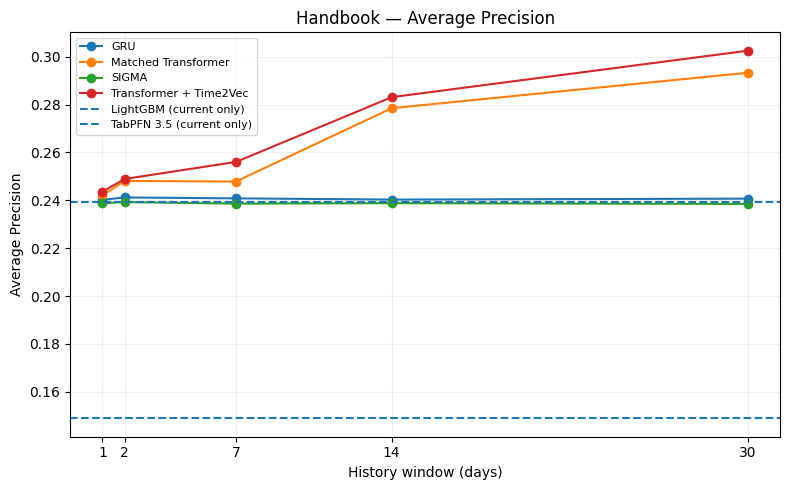

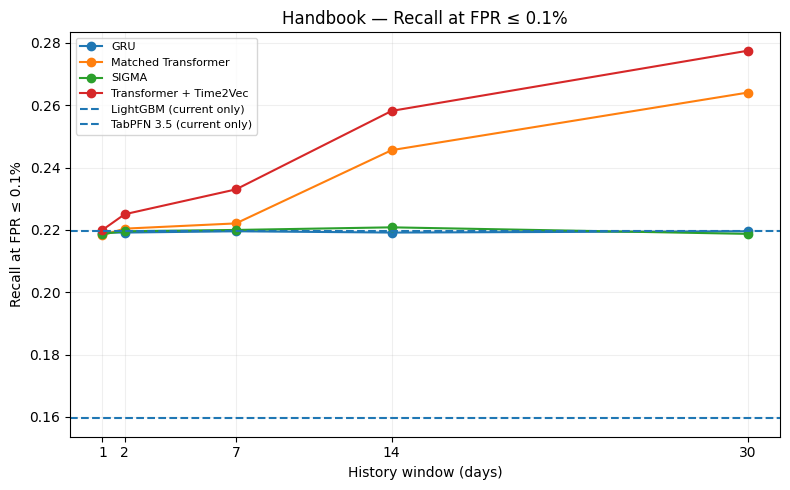

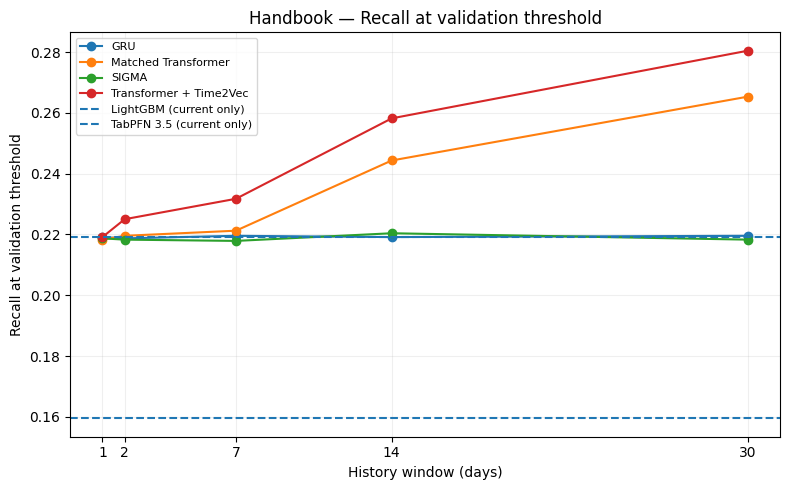

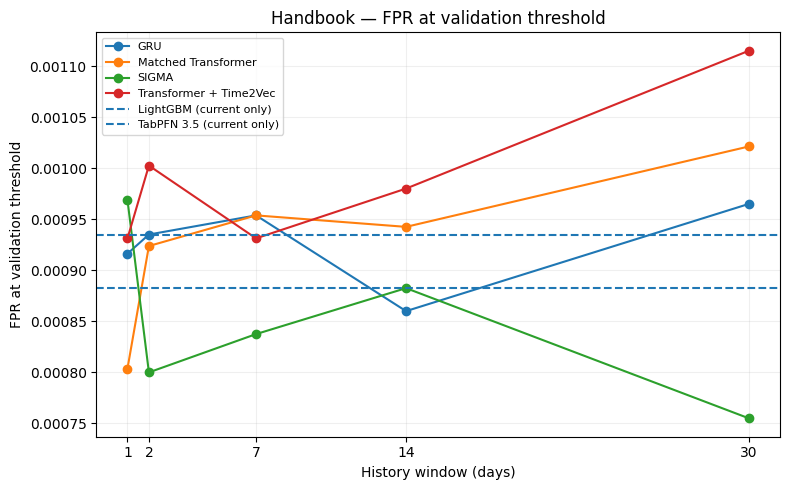

arm             gru   matched     sigma  time2vec  Time2Vec_minus_GRU_pp
seed days                                                               
0    1     0.240207  0.242011  0.238751  0.243615               0.340836
     2     0.241182  0.248074  0.239255  0.248908               0.772627
     7     0.240807  0.247846  0.238603  0.256021               1.521434
     14    0.240302  0.278475  0.238797  0.283080               4.277861
     30    0.240689  0.293293  0.238474  0.302485               6.179590

Completed: 22 / 22
Saved: /content/drive/MyDrive/26-2_AI_project/processed/handbook/four_encoders_tabpfn35_v1


In [19]:
result=progress()
assert len(result), '실험을 먼저 실행하세요'
display(result[['history_encoder','days','seed','classifier','AP','PR_AUC','Recall_at_FPR','fixed_recall','fixed_fpr','encoder_parameters']].sort_values(['days','history_encoder','classifier']))
summary=result.groupby(['history_encoder','classifier','days']).agg(AP=('AP','mean'),AP_std=('AP','std'),Recall_at_FPR=('Recall_at_FPR','mean'),fixed_recall=('fixed_recall','mean'),fixed_fpr=('fixed_fpr','mean'),n=('seed','nunique')).reset_index()
write_csv(OUT/'summary.csv',summary)
for metric,ylabel in [('AP','Average Precision'),('Recall_at_FPR','Recall at FPR ≤ 0.1%'),('fixed_recall','Recall at validation threshold'),('fixed_fpr','FPR at validation threshold')]:
    fig,ax=plt.subplots(figsize=(8,5))
    for name in NAMES.values():
        a=summary[(summary.history_encoder==name)&(summary.classifier=='TabPFN 3.5')].sort_values('days')
        if len(a): ax.plot(a.days,a[metric],marker='o',label=name)
    for clf in ['LightGBM','TabPFN 3.5']:
        a=summary[(summary.history_encoder=='Current only')&(summary.classifier==clf)]
        if len(a): ax.axhline(a[metric].iloc[0],linestyle='--',label=f'{clf} (current only)')
    ax.set(xticks=RUN_DAYS,xlabel='History window (days)',ylabel=ylabel,title=f'Handbook — {ylabel}')
    ax.grid(alpha=.2); ax.legend(fontsize=8); fig.tight_layout()
    for ext in ['png','svg']: fig.savefig(OUT/'plots'/f'{metric}.{ext}',dpi=180,bbox_inches='tight')
    plt.show(); plt.close(fig)
wide=result[result.arm!='current'].pivot(index=['seed','days'],columns='arm',values='AP')
if {'gru','time2vec'}<=set(wide.columns):
    wide['Time2Vec_minus_GRU_pp']=(wide['time2vec']-wide['gru'])*100
    display(wide); write_csv(OUT/'delta_vs_gru.csv',wide.reset_index())
print('Completed:',len(result),'/',len(PLAN)); print('Saved:',OUT)

### 해석
- AP가 주 지표. `Recall_at_FPR`은 Test ROC에서 계산한 진단값이고 운영 threshold는 Val에서 정한 `fixed_recall`, `fixed_fpr`로 별도 비교한다.
- Current only LightGBM vs TabPFN은 동일 3개 특징·동일 라벨 예산의 비교. 시계열 모델 vs LightGBM은 파이프라인 비교이며 분류기 자체의 우위만 뜻하지 않는다.
- SIGMA 원본 소스는 고정 commit으로 Colab에서 다운로드, 기존 부분 flip 변형 및 scan 유지. 네트워크 실패 시 해당 Part만 중단되며 다른 Part 실행 가능.
- TabPFN 컨텍스트는 재구성 가능하며 pretrained weights는 그대로 유지. 최종 TabPFN 객체 자체는 저장하지 않고 예측 및 행/Encoder를 저장한다.
- Test 결과를 바탕으로 구조를 다시 선택·조정하지 않는다. 추가 반복 검증은 별도 계획. 실제 데이터 대표성은 합성 데이터의 한계로 제한됨.